In [1]:
import numpy as np
import matplotlib.pyplot as plt

from results_loader import load_results, summary_table

# all with the adaptive scale; GATAS_adaptive is the reference (NSGA-II, PCA basis, free text coefficients)
CONFIGS = {"GATAS_adaptive": "NSGA-II (reference)", "GATAS_dct": "+ DCT text", "GATAS_jac": "+ Jacobian basis",
           "GATAS_jacdct": "+ Jacobian + DCT", "GATAS_cmaes": "CMA-ES", "GATAS_mocma": "MO-CMA-ES",
           "GATAS_cmaes_jacdct": "CMA-ES + Jacobian + DCT", "GATAS_mocma_jacdct": "MO-CMA-ES + Jacobian + DCT"}
THRESHOLDS = {"PESQ": 0.2, "SET_OVERLAP": 0.5}
records = load_results("../outputs/results", dataset="harvard", asr_model="whisper-tiny", methods=list(CONFIGS))
configs = [c for c in CONFIGS if records[c]]  # skip configurations without results yet

## Main table

Same 20 sentences, 200 queries per sentence, adaptive scale in all rows. `generations to found` is the mean first generation that meets the thresholds (budget: 10).

In [2]:
table = summary_table({CONFIGS[c]: records[c] for c in configs}).round(3)
table["generations to found"] = [np.mean([r["generation_found"] if r["generation_found"] is not None else 11 for r in records[c]]) for c in configs]
display(table)

,n,original fails %,test case found %,found % (original passes),lexical (WER),semantic,spectrogram,UTMOS,generations to found
NSGA-II (reference),20.0,30.0,100.0,100.000,0.374,0.332,0.082,3.808,11.00
+ DCT text,20.0,30.0,100.0,100.000,0.319,0.344,0.080,4.101,11.00
+ Jacobian basis,20.0,30.0,95.0,92.857,0.285,0.286,0.076,4.071,11.00
+ Jacobian + DCT,20.0,30.0,95.0,92.857,0.330,0.322,0.078,4.037,10.65
CMA-ES,20.0,30.0,95.0,92.857,0.204,0.248,0.074,4.174,11.00
MO-CMA-ES,20.0,30.0,100.0,100.000,0.416,0.389,0.094,3.851,11.00
CMA-ES + Jacobian + DCT,20.0,30.0,100.0,100.000,0.168,0.227,0.068,4.286,11.00
MO-CMA-ES + Jacobian + DCT,20.0,30.0,100.0,100.000,0.306,0.279,0.082,4.001,11.00


## Search progress

Best SET_OVERLAP in the archive among candidates with PESQ <= 0.2 (1 = nothing yet), per generation. The threshold is 0.5, so this shows how far each search gets; it is the optimizer's objective, not the success criterion (transcription differs).

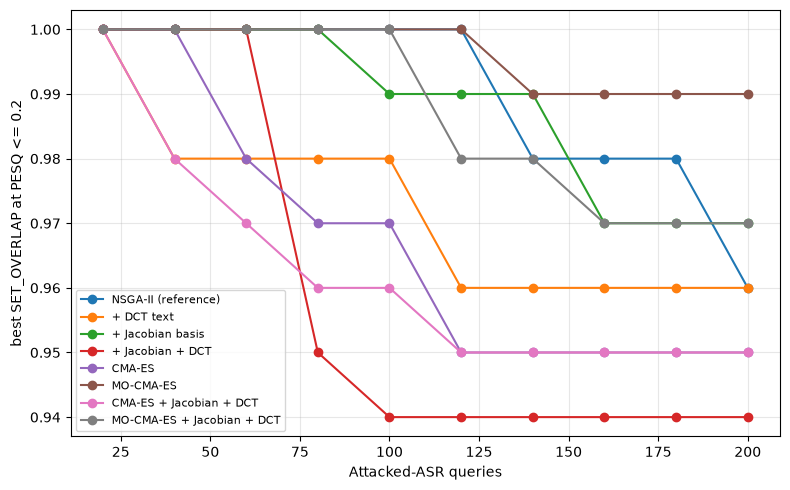

In [4]:
import json

def progress(recs):
    curves = []
    for r in recs:
        h = json.load(open(r["archive_history"]))
        pesq, overlap = h["objectives"].index("PESQ"), h["objectives"].index("SET_OVERLAP")
        curves.append([min([m[overlap] for m in a if m[pesq] <= THRESHOLDS["PESQ"]], default=1.0) for a in h["archive_per_generation"]])
    return np.mean(curves, axis=0)

plt.figure(figsize=(8, 5))
for c in configs:
    y = progress(records[c])
    plt.plot(np.arange(1, len(y) + 1) * 20, y, marker="o", label=CONFIGS[c])
plt.xlabel("Attacked-ASR queries")
plt.ylabel("best SET_OVERLAP at PESQ <= 0.2")
plt.grid(alpha=0.3)
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("_figures/ablation_space_progress.pdf", bbox_inches="tight")
